# European high-elo game: six-policy coach

An executed development report and one-game replay covering both teams, all ten players and every policy. **This is behavior and delivery evaluation, not a demonstrated win-rate gain.**

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from rift_research.game_review import notebook_section

ROOT = next(
    p
    for p in (Path.cwd(), *Path.cwd().parents)
    if (p / "pyproject.toml").exists() and (p / "common").exists()
)
REVIEW = ROOT / "data/research/european-final-game-review-20261110"
report = json.loads((REVIEW / "review.json").read_text())
decisions = pd.read_json(REVIEW / "candidate-decisions.json")
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

## What changed and what was frozen

The new state expresses public-stat leads and deficits explicitly and records measured alive fractions. Missing operands stay unknown. European games broaden the previous Korean corpus. Phase support screens out actions with too few examples at that stage of a game. The game below was reserved before fitting; selection uses development matches only. See [the mathematical design](../../docs/MATHEMATICAL_DESIGN.md) for the losses and assumptions.

**Changes tested:** 24 masked relative-strength/alive features in state v2; EUW data alongside retained Korean games; phase-specific empirical action support; softer class weights; development checkpoint selection; ordinary/consistent imitation, conservative return regression and IQL. Six models fit independently. Team/role conflicts are withheld without inventing an alternative.

,frozen setting
study_design,european-balanced-selection-v1
split_seed,42
optimizer_seed,42
steps_maximum,4000
checkpoint_interval,500
checkpoint_patience,3
selection,development gates then mean clean/cold identif...
notebook_match,EUW1_8034380954
reserved_european_matches,40
historical_reserved_matches,21


,model,state_schema,bundle_sha256
0,candidate,decision-state-v2,85693100e670aa2607de601ea29e8fb91a68d0c57f7d95...
1,previous,decision-state-v1,84078656b685171ea52f471f41a563a43b7b86cc9d0537...


,accepted_matches,transitions,accepted_european_matches,excluded_matches,exclusion_reasons
0,1950,559200,310,13,{'No complete actor episodes with supported be...


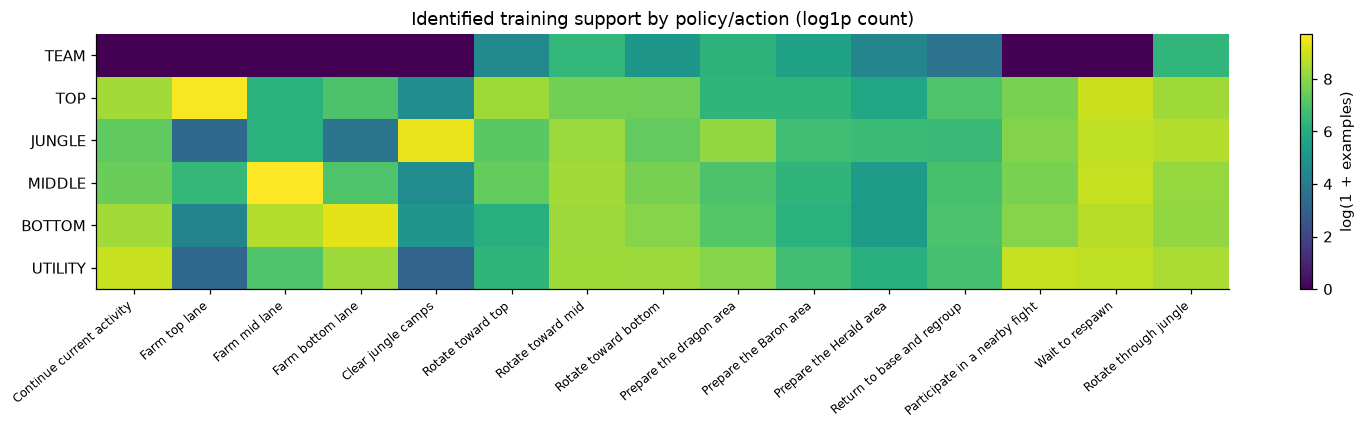

,scope,identified_training_rows,supported_action_classes
0,TEAM,2394,8
1,TOP,45584,15
2,JUNGLE,40931,15
3,MIDDLE,43747,15
4,BOTTOM,43101,15
5,UTILITY,44217,15


In [2]:
notebook_section(REVIEW, "development")

## Development comparison

Imitation predicts recorded activities; conservative return regression fits observed discounted terminal outcomes; IQL uses critic/value learning and an advantage-weighted actor. The consistency variants penalize some changes under missing history. Every algorithm remains eligible. These metrics measure activity agreement and missing-history robustness. The previous-product comparison changes multiple factors, so it is not an isolated ablation.

,scope,candidate,clean_F1,cold_F1,switching,retention,concentration,score,passed,selected
0,TEAM,cql-return-003,0.228,0.220,0.289,1.0,0.308,0.224,True,False
1,TEAM,bc,0.328,0.244,0.152,1.0,0.359,0.292,True,False
2,TEAM,cql-consistent,0.239,0.235,0.250,1.0,0.290,0.229,True,False
3,TEAM,bc-consistent,0.311,0.251,0.139,1.0,0.401,0.273,True,False
4,TEAM,bc-phase,0.330,0.244,0.147,1.0,0.359,0.293,True,True
5,TEAM,bc-phase-softweights,0.276,0.228,0.008,1.0,0.485,0.268,True,False
6,TEAM,bc-consistent-seed43,0.315,0.283,0.144,1.0,0.417,0.287,True,False
7,TEAM,iql-phase,0.307,0.226,0.071,1.0,0.490,0.281,True,False
8,TOP,cql-return-003,0.148,0.163,0.204,1.0,0.507,0.135,True,False
9,TOP,bc,0.175,0.202,0.046,1.0,0.544,0.180,True,True


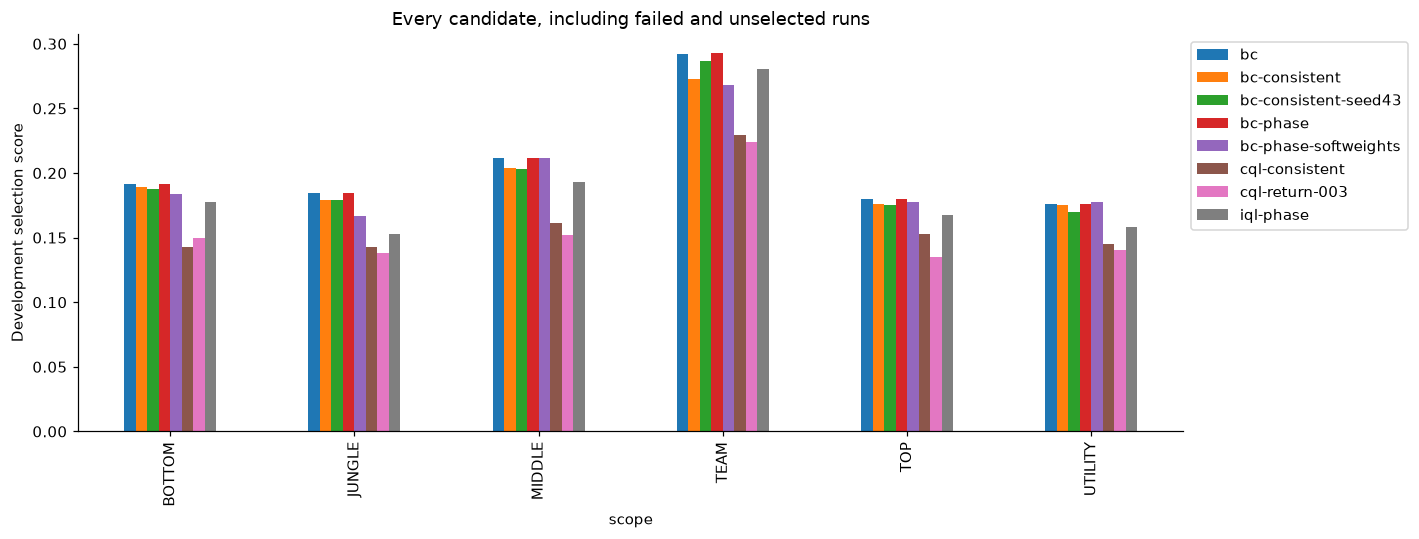

In [3]:
notebook_section(REVIEW, "selection")

## Learning curves and early stopping

Longer training can overfit the reconstructed labels. Every 500 updates, checkpoints are evaluated on development data under the same clean/cold score and gates. Training stops after three nonimproving checkpoints; the saved weights come from the best checkpoint, which can precede the last update.

These curves belong to the original training stage. This revision reselects among those saved networks using equal-weight European/Korean development scores; it performs **zero additional optimizer updates** and does not retune checkpoints.

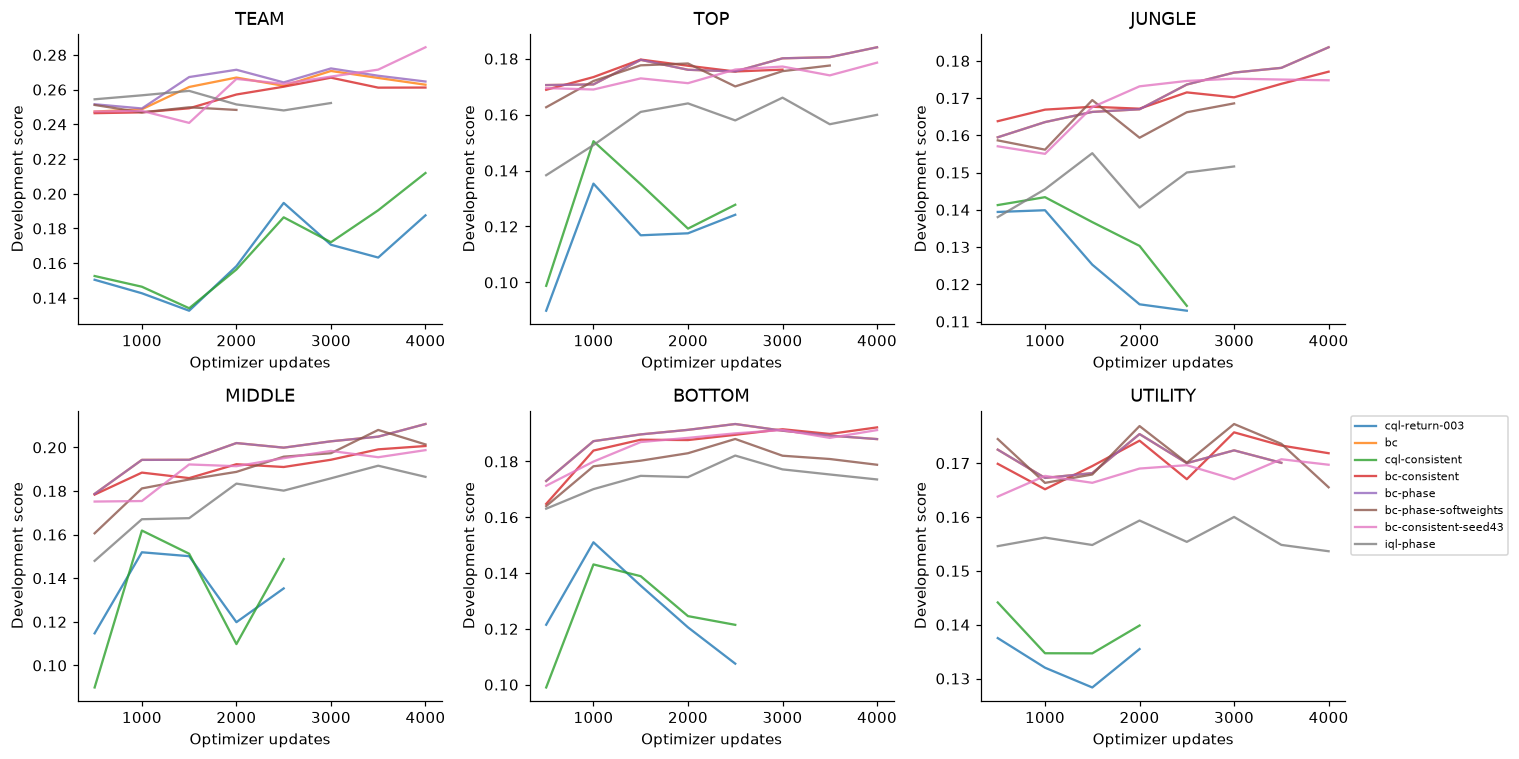

,scope,selected,completed_updates,restored_checkpoint,development_score
0,TEAM,bc-phase,4000,3000,0.292809
1,TOP,bc,4000,4000,0.180194
2,JUNGLE,bc,4000,4000,0.184897
3,MIDDLE,bc-phase-softweights,4000,3500,0.211886
4,BOTTOM,bc,4000,2500,0.191131
5,UTILITY,bc-phase-softweights,4000,3000,0.177351


In [4]:
notebook_section(REVIEW, "learning")

## Independent European holdout

The broader held-out European cohort is separate from training/development. Match-level uncertainty and sparse macro evidence limit conclusions.

,model,scope,identified_rows,identified_f1,identified_agreement,coverage,identified_majority_agreement,f1_lower,f1_upper
0,previous,TEAM,68,0.334,0.353,1.0,0.206,0.213,0.414
1,candidate,TEAM,68,0.322,0.353,1.0,0.206,0.211,0.380
2,previous,TOP,1180,0.170,0.500,1.0,0.342,0.154,0.188
3,candidate,TOP,1180,0.175,0.505,1.0,0.342,0.157,0.195
4,previous,JUNGLE,1130,0.199,0.406,1.0,0.300,0.180,0.234
5,candidate,JUNGLE,1130,0.192,0.381,1.0,0.300,0.177,0.226
6,previous,MIDDLE,1184,0.185,0.541,1.0,0.365,0.171,0.201
7,candidate,MIDDLE,1184,0.208,0.559,1.0,0.365,0.193,0.227
8,previous,BOTTOM,1145,0.174,0.419,1.0,0.251,0.161,0.187
9,candidate,BOTTOM,1145,0.181,0.439,1.0,0.251,0.167,0.195


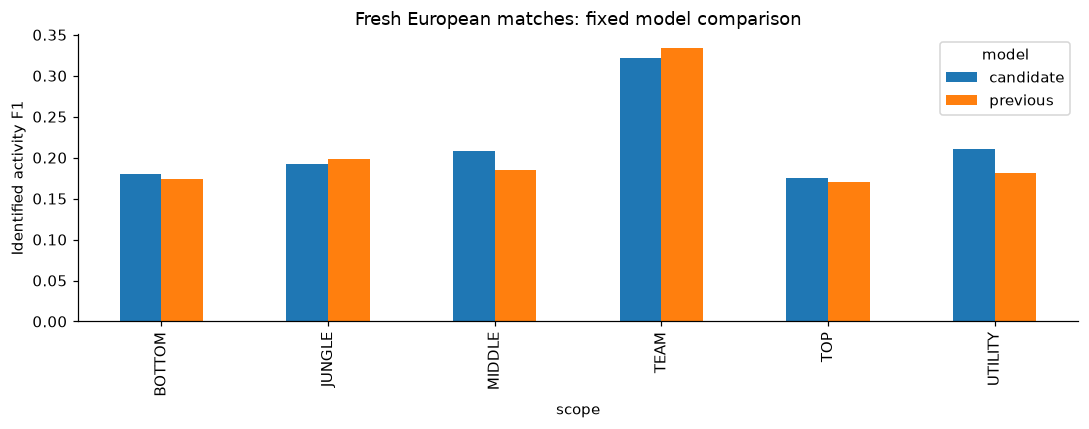

,scope,point_difference,f1_difference_95,valid_resamples,identified_rows
0,TEAM,-0.011813,"[-0.06223970655742914, 0.03126073941059228]",1000,68
1,TOP,0.005166,"[-0.011831187310904916, 0.022291703585029365]",1000,1180
2,JUNGLE,-0.006653,"[-0.019125783714661542, 0.005609959648472427]",1000,1130
3,MIDDLE,0.022965,"[0.009262474232508927, 0.039416719940693595]",1000,1184
4,BOTTOM,0.006333,"[-0.0025031835957374108, 0.01548829544360635]",1000,1145
5,UTILITY,0.029074,"[0.00788518127374717, 0.053590673584509634]",1000,1175


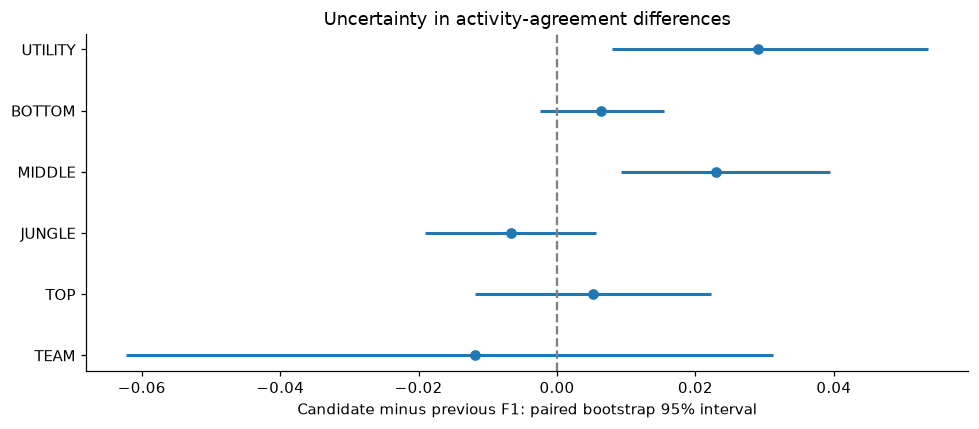

Fixed-product comparison on unseen European matches. Paired bootstrap resamples whole matches; recurring players can remain dependent. F1 measures recorded-activity agreement, not strategic quality or win rate. Multiple development changes prevent isolated causal attribution.

In [5]:
notebook_section(REVIEW, "holdout")

## What the first test taught us

A failed evaluation remains part of the evidence. If a later development selection responds to that finding, it needs a fresh test before claiming generalization.

The first mixed-region study improved UTILITY activity agreement but reduced TEAM agreement on its reserved European cohort. European TEAM development had 87 identified targets versus 485 Korean targets. The revised product selects among the same 48 saved networks using equal-weight regional development scores and both regional gates, with zero additional optimizer updates. That first cohort is now consulted retrospective evidence. The revised selection was frozen before collecting/reserving a second cohort; the final notebook game belongs to this fresh second cohort. No test predictions choose a candidate.

**First study's reserved European result (before the revised selection):**

,model,scope,identified_rows,identified_f1,identified_agreement,coverage,identified_majority_agreement,f1_lower,f1_upper
0,previous,TEAM,61,0.316,0.508,1.0,0.213,0.219,0.447
1,candidate,TEAM,61,0.272,0.426,1.0,0.213,0.172,0.374
2,previous,TOP,1209,0.168,0.474,1.0,0.325,0.149,0.187
3,candidate,TOP,1209,0.175,0.481,1.0,0.325,0.154,0.193
4,previous,JUNGLE,1052,0.210,0.413,1.0,0.268,0.192,0.233
5,candidate,JUNGLE,1052,0.214,0.402,1.0,0.268,0.196,0.239
6,previous,MIDDLE,1127,0.196,0.541,1.0,0.362,0.179,0.216
7,candidate,MIDDLE,1127,0.194,0.542,1.0,0.362,0.178,0.210
8,previous,BOTTOM,1145,0.178,0.460,1.0,0.287,0.165,0.189
9,candidate,BOTTOM,1145,0.186,0.478,1.0,0.287,0.171,0.202


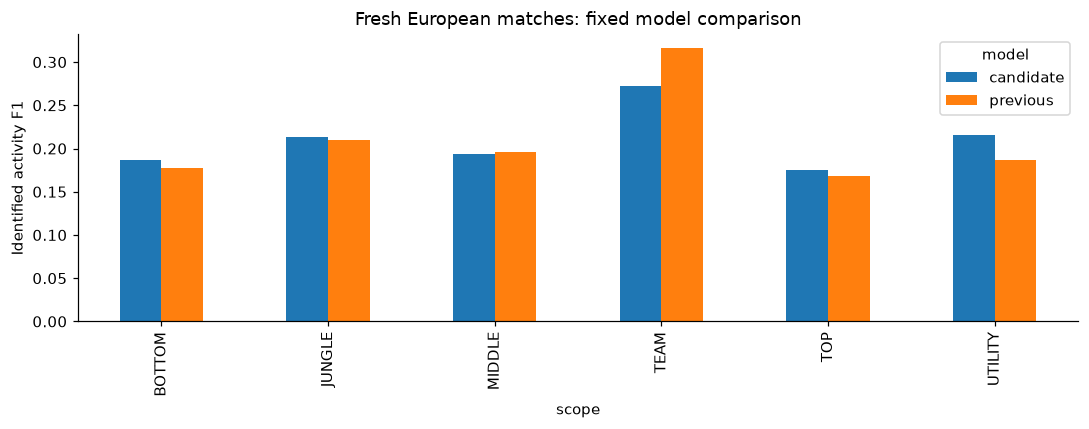

,scope,point_difference,f1_difference_95,valid_resamples,identified_rows
0,TEAM,-0.044666,"[-0.1251961243955504, -0.011351622166009968]",1000,61
1,TOP,0.006836,"[-0.007353438376058472, 0.020791570014248785]",1000,1209
2,JUNGLE,0.003197,"[-0.004663336068423318, 0.011598790297784945]",1000,1052
3,MIDDLE,-0.002415,"[-0.013737397551497232, 0.007373519229598557]",1000,1127
4,BOTTOM,0.008556,"[-0.002528599636630912, 0.019439508633339313]",1000,1145
5,UTILITY,0.029158,"[0.011635383949413715, 0.048022032632075905]",1000,1105


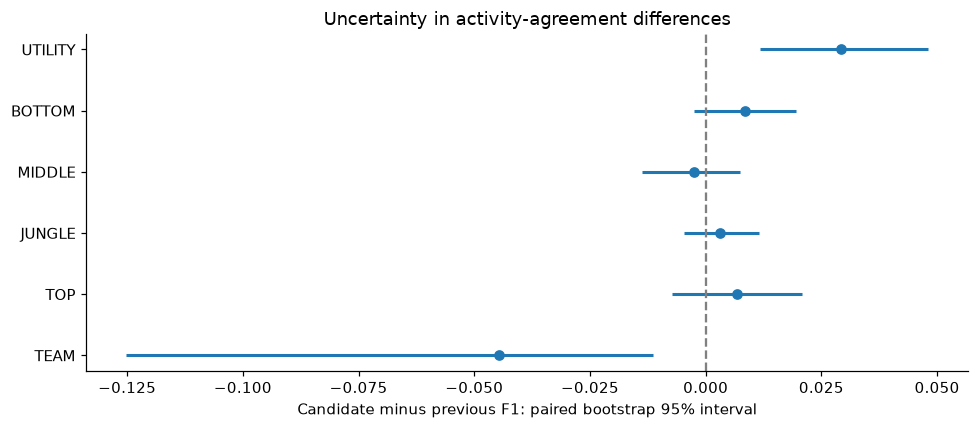

Fixed-product comparison on unseen European matches. Paired bootstrap resamples whole matches; recurring players can remain dependent. F1 measures recorded-activity agreement, not strategic quality or win rate. Multiple development changes prevent isolated causal attribution.

,scope,candidate,region,identified_rows,clean_F1,cold_F1,region_score,selected
0,TEAM,cql-return-003,Europe,87,0.306,0.270,0.258,False
1,TEAM,cql-return-003,Korea,485,0.219,0.218,0.190,False
2,TEAM,bc,Europe,87,0.367,0.295,0.317,False
3,TEAM,bc,Korea,485,0.321,0.244,0.267,False
4,TEAM,cql-consistent,Europe,87,0.235,0.324,0.254,False
5,TEAM,cql-consistent,Korea,485,0.238,0.221,0.205,False
6,TEAM,bc-consistent,Europe,87,0.300,0.296,0.285,False
7,TEAM,bc-consistent,Korea,485,0.306,0.243,0.260,False
8,TEAM,bc-phase,Europe,87,0.367,0.295,0.317,True
9,TEAM,bc-phase,Korea,485,0.323,0.244,0.269,True


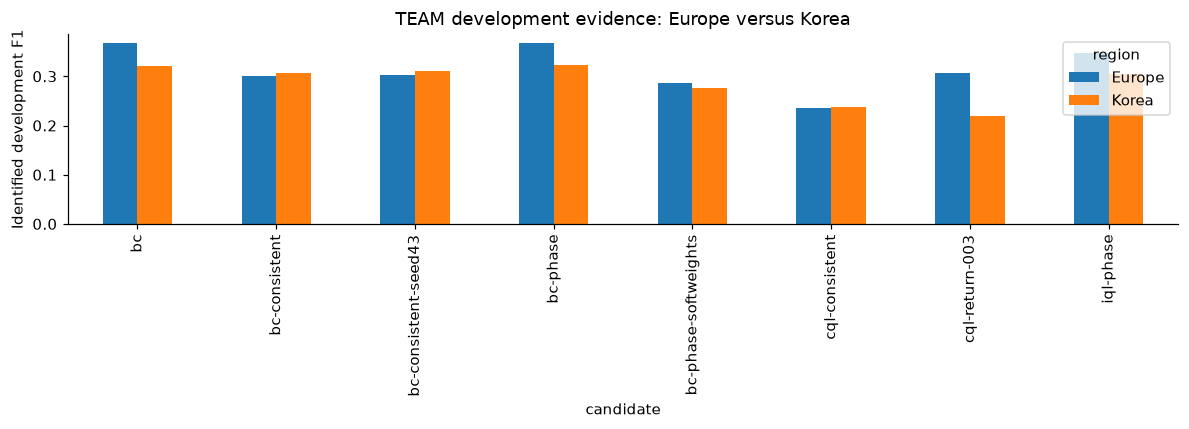

,scope,revised_selection,balanced_development_score,passed_both_region_gates
0,TEAM,bc-phase,0.293,True
1,TOP,bc,0.180,True
2,JUNGLE,bc,0.185,True
3,MIDDLE,bc-phase-softweights,0.212,True
4,BOTTOM,bc,0.191,True
5,UTILITY,bc-phase-softweights,0.177,True


**Fresh-test status:** The temporary Riot HTTP 401 was resolved after the local key changed. Seventy-three additional distinct European games were downloaded. Forty were frozen before evaluation, all survived dataset validation, and the revised selection was evaluated once against the previous coach. MIDDLE and UTILITY activity-F1 intervals are above zero; the other four scope differences include zero. Earlier game dates/patches, recurring players and coarse labels limit interpretation.

**Fresh-cohort comparison of the two selection rules, using the same trained candidate bank:**

,scope,point_difference,f1_difference_95,valid_resamples,identified_rows
0,TEAM,0.013435,"[0.0, 0.03649111358774187]",1000,68
1,TOP,0.000000,"[0.0, 0.0]",1000,1180
2,JUNGLE,0.000000,"[0.0, 0.0]",1000,1130
3,MIDDLE,0.016950,"[-8.248172825032319e-05, 0.03829683627073183]",1000,1184
4,BOTTOM,0.000000,"[0.0, 0.0]",1000,1145
5,UTILITY,0.000000,"[0.0, 0.0]",1000,1175


**Release decision:** Activated the verified six-policy product as an experimental offline candidate, retaining the previous pointer and all weights. The release is not a proven winning strategy or calibrated win predictor. TEAM and JUNGLE point estimates remain slightly below the previous model on the fresh cohort.

In [6]:
notebook_section(REVIEW, "followup")

## The reserved European game

Current verified Challenger roster membership establishes the collection account's current tier, not all participants' historical ranks. Roles shown here are retrospective.

,version,upstream_sha256,sha256,patch
0,16.21.1,72b5c85ae1bbddf471f2ac255f47b214a2e29a87f7361d...,9b3a337498b7bbcf1067e9fefd5a624f64f48dbeace7e1...,16.21


,platform,current_tier,participant_ids,snapshot_sha256
0,euw1,CHALLENGER,[8],3e0a98cfb5e32468390c4ce1f8c2e6466d978783290aeb...


,0
match_id,EUW1_8034380954
patch,16.21.834.2754
queue,420
duration_seconds,1548
game_creation_utc,2026-11-03T01:25:49.603000+00:00
winning_team,200
raw_sha256,5230577277041803b1956bcc7bf2ee3d47c33f96e55211...


,participantId,teamId,teamPosition,championName
0,1,100,TOP,Karthus
1,2,100,JUNGLE,MonkeyKing
2,3,100,MIDDLE,Gwen
3,4,100,BOTTOM,Yunara
4,5,100,UTILITY,Pyke
5,6,200,TOP,Garen
6,7,200,JUNGLE,Talon
7,8,200,MIDDLE,Taliyah
8,9,200,BOTTOM,Aphelios
9,10,200,UTILITY,Lulu


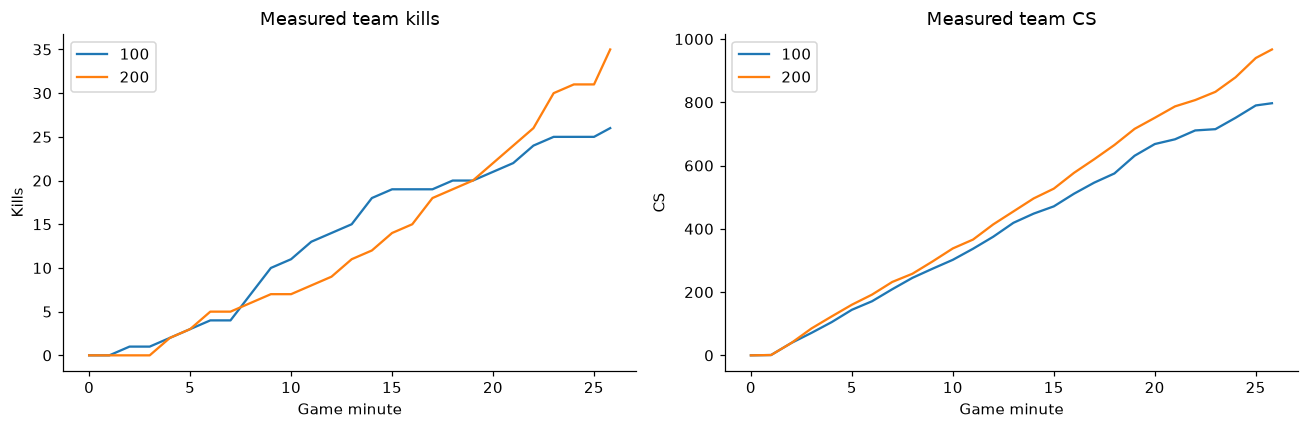

In [7]:
notebook_section(REVIEW, "game")

## Team direction over time

Two team policies are evaluated, one for each side. Recorded future activity is shown only for evaluation and remains unresolved when evidence is ambiguous.

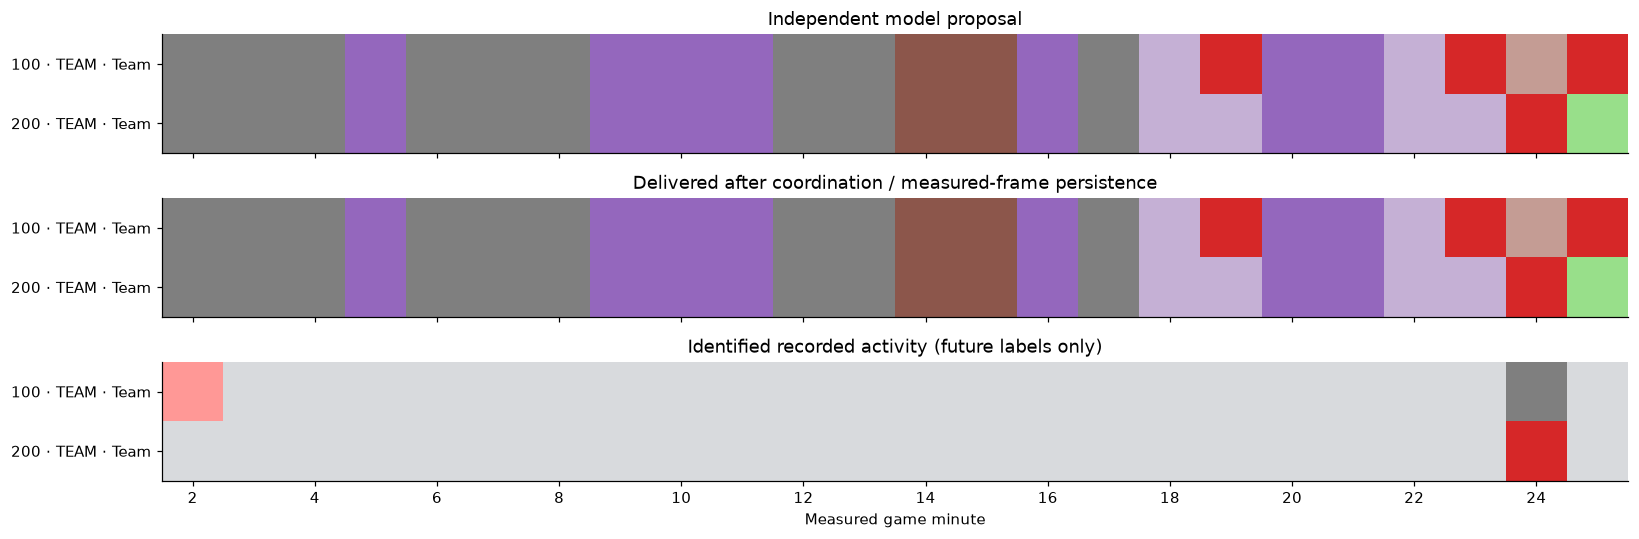

,color_index,activity
0,0,Continue current activity
1,1,Farm top lane
2,2,Farm mid lane
3,3,Farm bottom lane
4,4,Clear jungle camps
5,5,Rotate toward top
6,6,Rotate toward mid
7,7,Rotate toward bottom
8,8,Prepare the dragon area
9,9,Prepare the Baron area


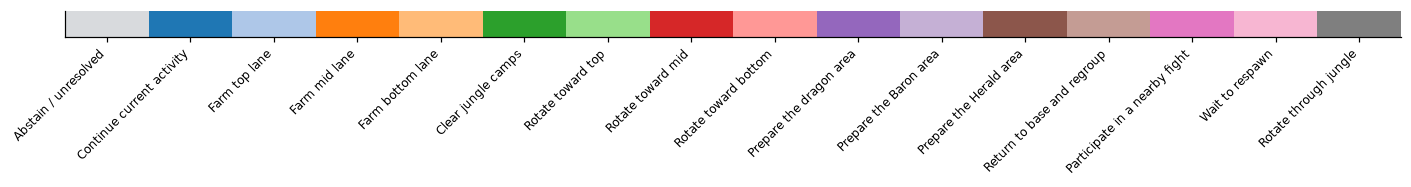

In [8]:
notebook_section(REVIEW, "teams")

## All ten players: recommendations versus measured activity

Each player's role specialist is evaluated alongside the team proposal. Light gray means abstention or unresolved evidence. An observed action is not necessarily the best action.

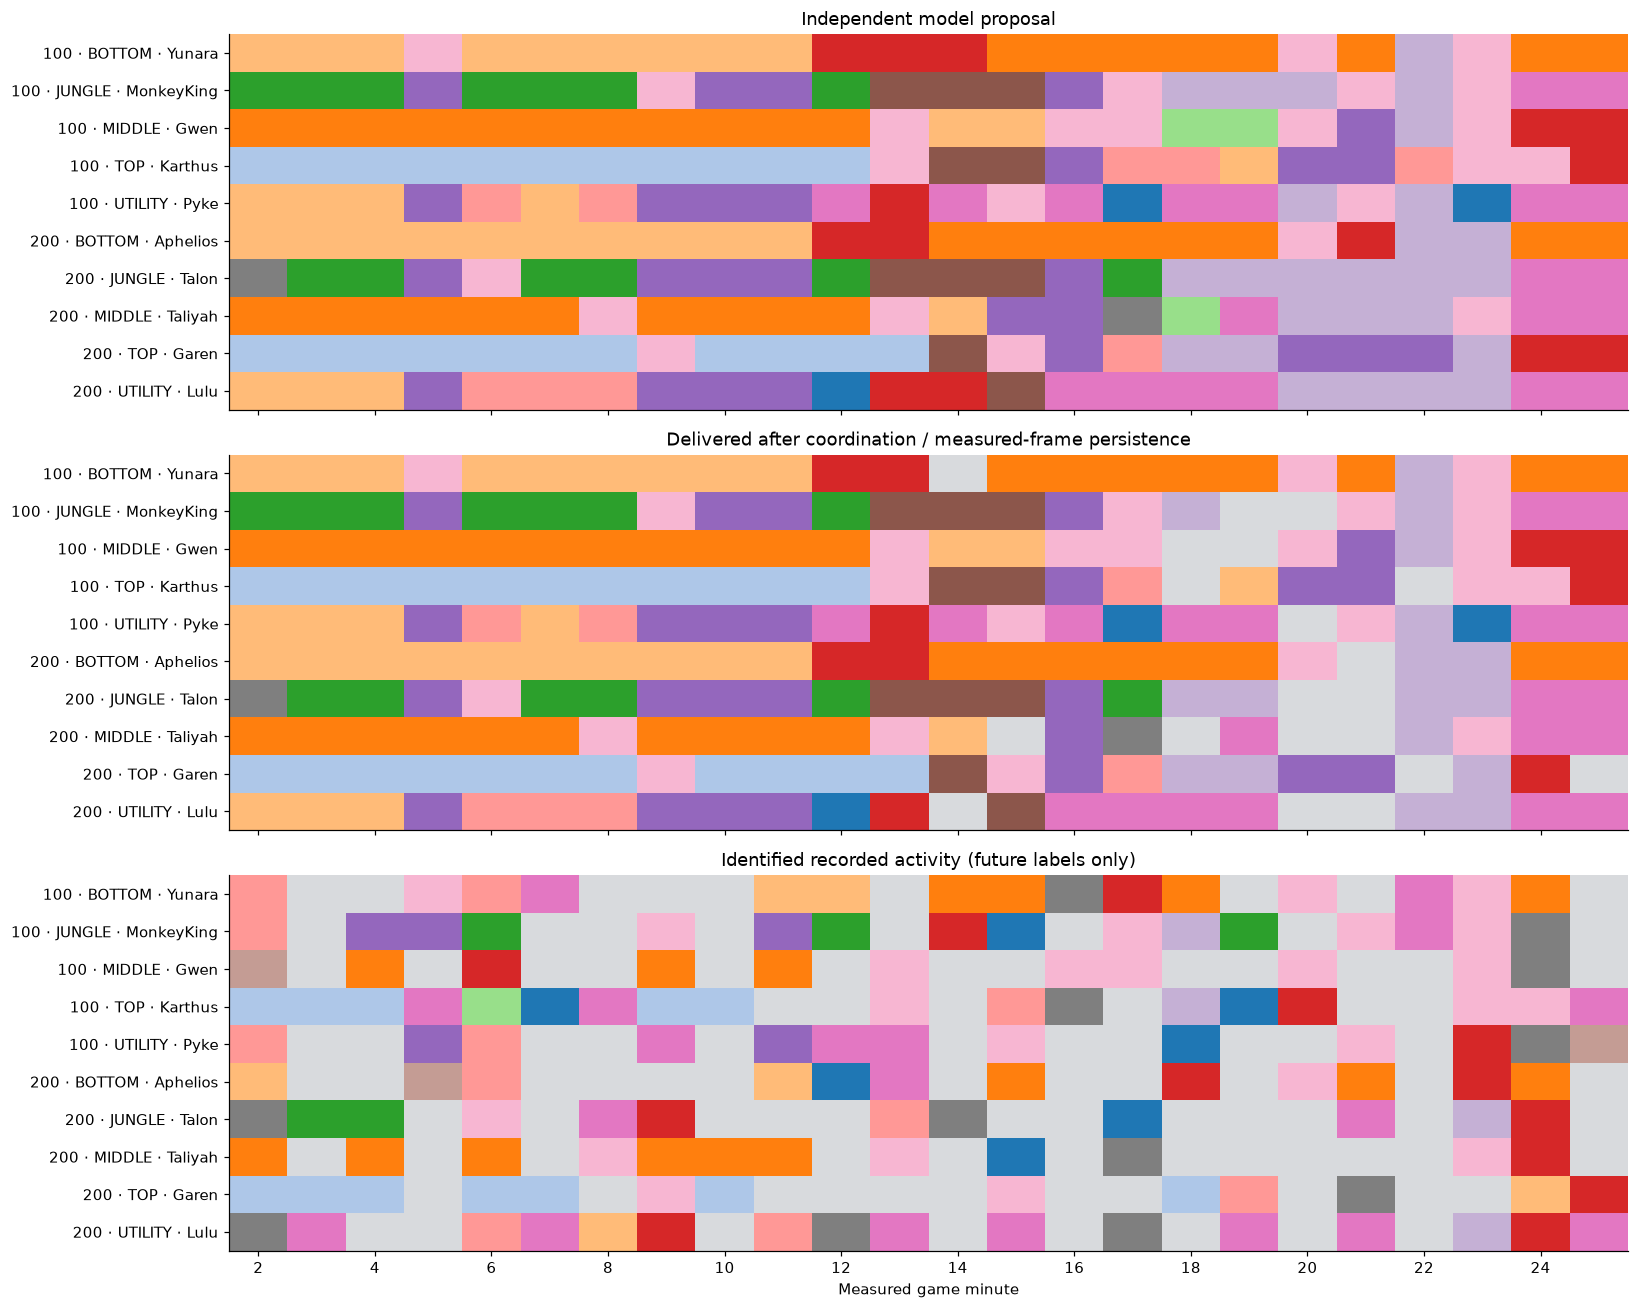

,color_index,activity
0,0,Continue current activity
1,1,Farm top lane
2,2,Farm mid lane
3,3,Farm bottom lane
4,4,Clear jungle camps
5,5,Rotate toward top
6,6,Rotate toward mid
7,7,Rotate toward bottom
8,8,Prepare the dragon area
9,9,Prepare the Baron area


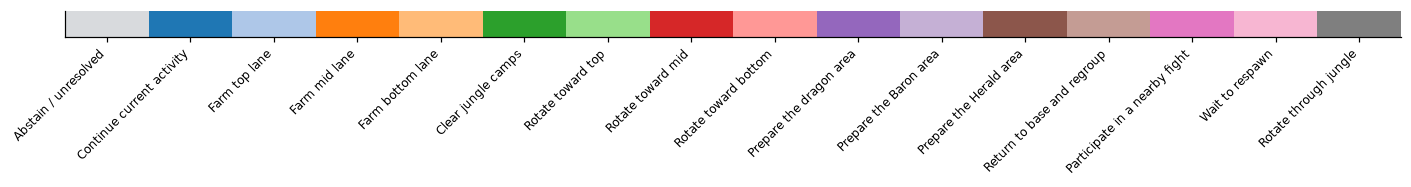

In [9]:
notebook_section(REVIEW, "players")

## Coverage, concentration and coordination

Coverage is measured after conflict withholding and measured-frame persistence. Forced respawn is separated from voluntary advice.

,model,scope,identified_n,raw_coverage,served_coverage,voluntary_coverage,voluntary_top_share,identified_F1
0,candidate,TEAM,3,1.0,1.000,1.000,0.375,0.250
1,candidate,TOP,31,1.0,0.917,0.907,0.564,0.185
2,candidate,JUNGLE,28,1.0,0.917,0.907,0.333,0.335
3,candidate,MIDDLE,23,1.0,0.875,0.850,0.618,0.321
4,candidate,BOTTOM,27,1.0,0.958,0.955,0.452,0.217
5,candidate,UTILITY,29,1.0,0.917,0.913,0.310,0.279
6,previous,TEAM,3,1.0,1.000,1.000,0.354,0.333
7,previous,TOP,31,1.0,0.917,0.907,0.538,0.175
8,previous,JUNGLE,28,1.0,0.917,0.907,0.333,0.299
9,previous,MIDDLE,23,1.0,1.000,1.000,0.525,0.386


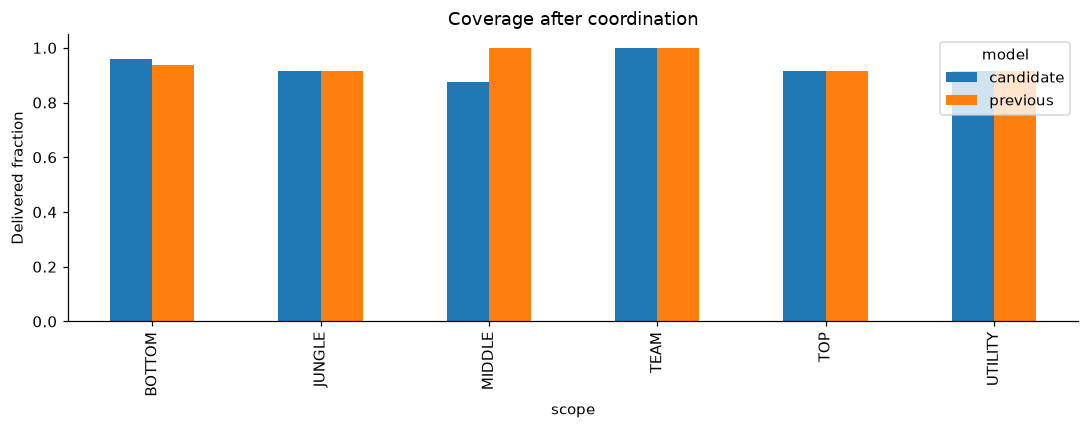

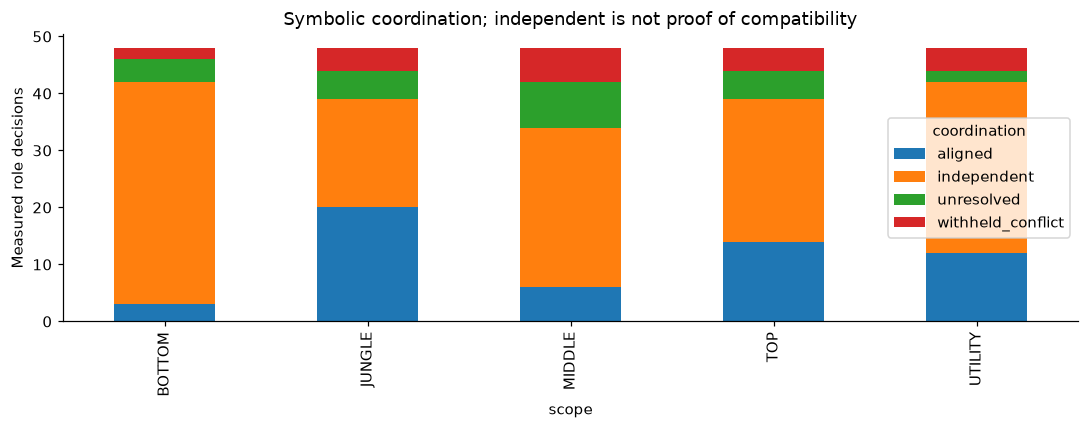

In [10]:
notebook_section(REVIEW, "coverage")

## Agreement by policy

F1 and confusion matrices use identified targets only. Missing support and unresolved team targets remain visible.

,model,scope,identified_n,identified_F1
0,candidate,TEAM,3,0.250
1,candidate,TOP,31,0.185
2,candidate,JUNGLE,28,0.335
3,candidate,MIDDLE,23,0.321
4,candidate,BOTTOM,27,0.217
5,candidate,UTILITY,29,0.279
6,previous,TEAM,3,0.333
7,previous,TOP,31,0.175
8,previous,JUNGLE,28,0.299
9,previous,MIDDLE,23,0.386


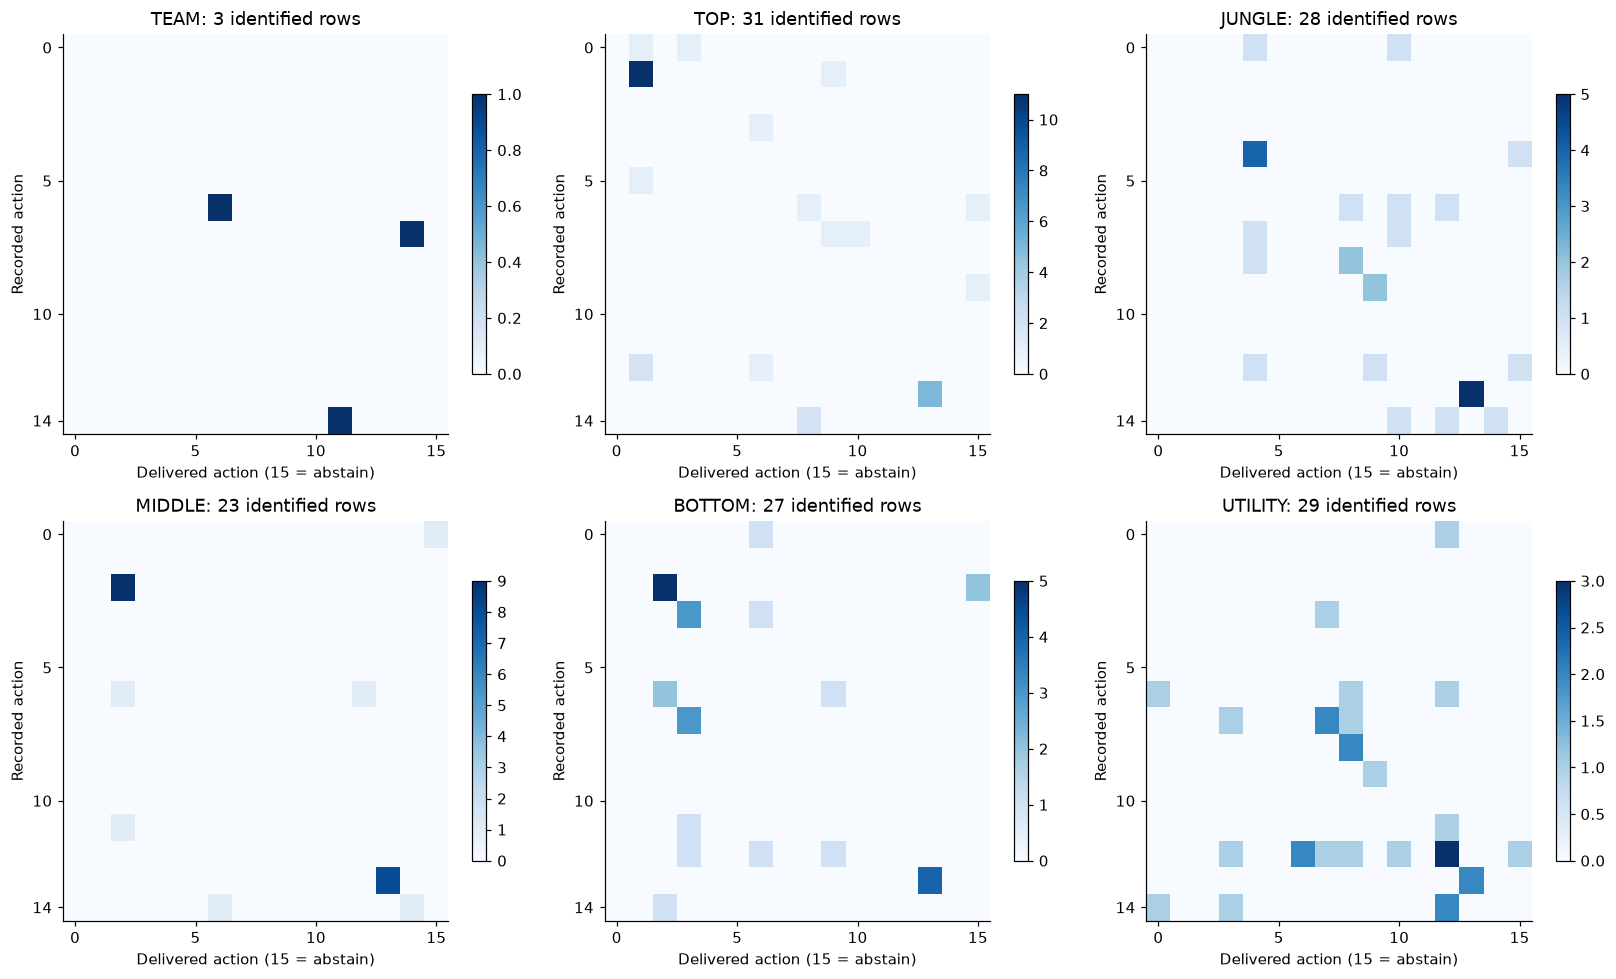

In [11]:
notebook_section(REVIEW, "agreement")

## Inspect individual recommendations

This table includes the instruction, prerequisite checks, independent role proposal, team proposal and served result. Use the data frame to inspect any player or minute.

In [12]:
notebook_section(REVIEW, "decisions")

,minute,team,scope,champion,raw_action,macro_action,served_action,observed_action,identified,coordination,instruction,check
0,2.000383,100,TEAM,Team,Rotate through jungle,Abstain / unresolved,Rotate through jungle,Rotate toward bottom,True,team_only,Reposition through jungle toward your next tas...,"Check vision, visible opponents and lane prior..."
1,2.000383,100,TOP,Karthus,Farm top lane,Rotate through jungle,Farm top lane,Farm top lane,True,independent,Stay with top-lane income: collect reachable m...,"Check the wave, visible threats and whether an..."
2,2.000383,100,JUNGLE,MonkeyKing,Clear jungle camps,Rotate through jungle,Clear jungle camps,Rotate toward bottom,True,independent,Work through available jungle camps while keep...,"Camp availability, lane pressure and route saf..."
3,2.000383,100,MIDDLE,Gwen,Farm mid lane,Rotate through jungle,Farm mid lane,Return to base and regroup,True,independent,Stay with mid-lane income: collect reachable m...,"Check the wave, visible threats and whether an..."
4,2.000383,100,BOTTOM,Yunara,Farm bottom lane,Rotate through jungle,Farm bottom lane,Rotate toward bottom,True,independent,Stay with bottom-lane income: collect reachabl...,"Check the wave, visible threats and whether an..."
5,2.000383,100,UTILITY,Pyke,Farm bottom lane,Rotate through jungle,Farm bottom lane,Rotate toward bottom,True,independent,Stay with bottom-lane income: collect reachabl...,"Check the wave, visible threats and whether an..."
6,2.000383,200,TEAM,Team,Rotate through jungle,Abstain / unresolved,Rotate through jungle,Continue current activity,False,team_only,Reposition through jungle toward your next tas...,"Check vision, visible opponents and lane prior..."
7,2.000383,200,TOP,Garen,Farm top lane,Rotate through jungle,Farm top lane,Farm top lane,True,independent,Stay with top-lane income: collect reachable m...,"Check the wave, visible threats and whether an..."
8,2.000383,200,JUNGLE,Talon,Rotate through jungle,Rotate through jungle,Rotate through jungle,Rotate through jungle,True,aligned,Reposition through jungle toward your next tas...,"Check vision, visible opponents and lane prior..."
9,2.000383,200,MIDDLE,Taliyah,Farm mid lane,Rotate through jungle,Farm mid lane,Farm mid lane,True,independent,Stay with mid-lane income: collect reachable m...,"Check the wave, visible threats and whether an..."


Load all decisions with `decisions = pd.read_json(REVIEW / 'candidate-decisions.json')`; filter `actor`, `scope`, `team` and `time` to inspect any player.

## Conclusions and limits

Read the measured improvements and regressions together. One game's result does not establish the causal value of any recommendation.

In [13]:
notebook_section(REVIEW, "conclusion")

**Independent pipeline check:** raw one-game replay agrees exactly with saved batch evaluation predictions.

,rows,players,teams,exact_raw_replay_equals_frozen_evaluation
candidate,288,10,2,True
previous,288,10,2,True


model,candidate,previous,candidate_minus_previous
scope,,,
BOTTOM,0.217,0.206,0.010
JUNGLE,0.335,0.299,0.037
MIDDLE,0.321,0.386,-0.065
TEAM,0.250,0.333,-0.083
TOP,0.185,0.175,0.010
UTILITY,0.279,0.278,0.002


- One retrospectively replayed game cannot establish strategic utility or a win-rate gain.
- Roles are retrospective; current Challenger membership does not certify historical rank of all ten players.
- Only measured frames are replayed, typically one minute apart; five-second live persistence is not simulated.
- Activity agreement describes behavior, not the correctness of alternative actions.
- No vision, wave, camp safety or intermediate actions are fabricated. Scores are not win probabilities.

**Next evidence needed:** broader chronological/player-disjoint tests, decision review with only causal information, live-input acceptance and a predefined prospective outcome comparison. A successful replay does not certify winning strategy.

## Reproduce the replay

The cell below reloads the saved models and raw game without any network access. It checks that every recorded recommendation is reproducible.

In [14]:
from offline_rift.inference.coach import MacroCoach
from rift_common.artifacts import file_digest
from rift_common.items import ItemCatalog
from rift_research.game_review import replay_game

catalog_path = REVIEW / "replay-item-catalog.json"
assert file_digest(catalog_path) == report["replay_catalog"]["sha256"]
catalog = ItemCatalog(json.loads(catalog_path.read_text()))
assert file_digest(Path(report["raw_path"])) == report["raw_sha256"]
payload = json.loads(Path(report["raw_path"]).read_text())
for name, model in report["models"].items():
    assert file_digest(Path(model["bundle"]) / "coach.json") == model["sha256"]
    replayed = replay_game(payload, MacroCoach(model["bundle"]), catalog=catalog)
    saved = json.loads((REVIEW / f"{name}-decisions.json").read_text())
    assert replayed == saved, name
print("Verified: all policies, both teams, all ten players; no downloads or fitting.")

Verified: all policies, both teams, all ten players; no downloads or fitting.
